Для аккуратных, тонко настроенных графиков нужен **объектно-ориентированный** подход

## Объектно ориентированный подход - `Figure and Axes`

Вместо `plt`, работаем с `Figure and Axes`, для настройки каждого элемента

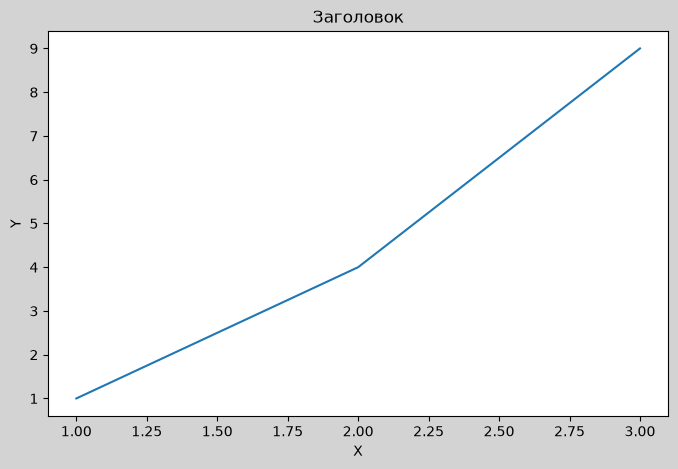

In [6]:
import matplotlib.pyplot as plt

# fig — объект Figure: вся фигура целиком.
# В ней могут находиться одна или несколько областей с графиками.
# ax — объект Axes: область, в которой строится график.
# Через него настраиваются линии, заголовок, оси и другие элементы.
fig, ax = plt.subplots(figsize=(8, 5))

fig.set_facecolor(color="lightgrey")

ax.plot([1, 2, 3], [1, 4, 9])

ax.set_title("Заголовок")
ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

## Несколько осей на одной графике

[[<Axes: > <Axes: >]
 [<Axes: > <Axes: >]
 [<Axes: > <Axes: >]]


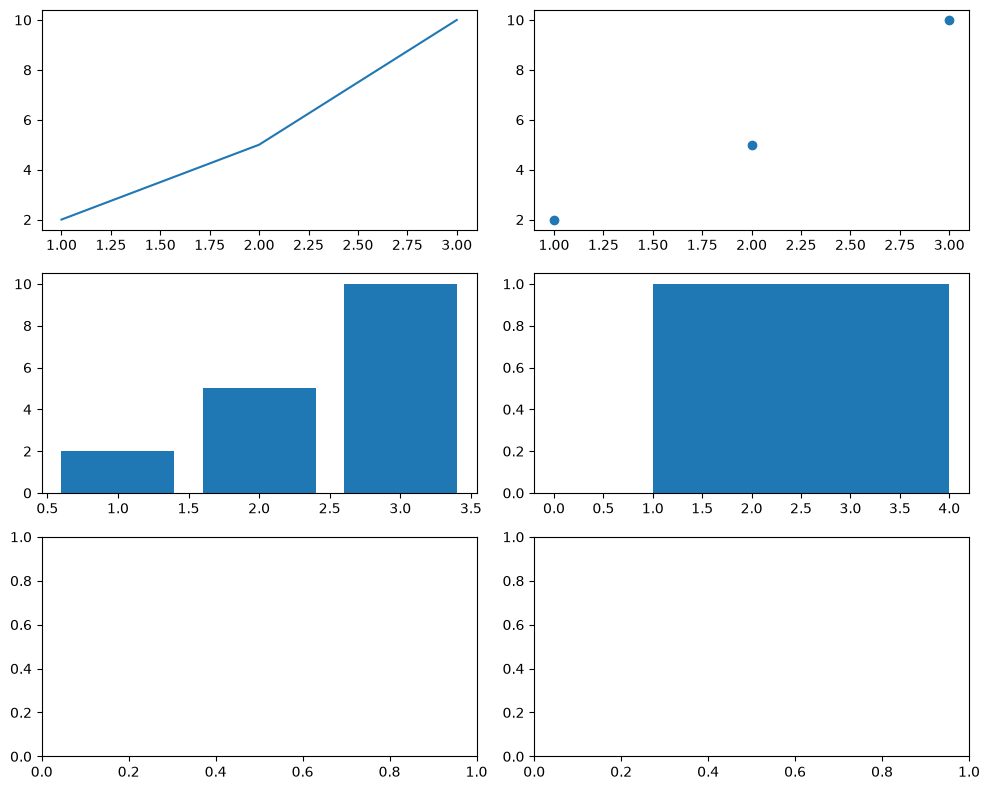

In [17]:
# 3 - строки, 2 - столбца
fig, axes = plt.subplots(3, 2, figsize=(10, 8))

print(axes)

x = [1, 2, 3]
y = [2, 5, 10]

axes[0, 0].plot(x, y)
axes[0, 1].scatter(x, y)
axes[1, 0].bar(x, y)
axes[1, 1].hist(x, bins=[0, 1, 2, 3, 4])

fig.tight_layout()

## Вторая ось Y

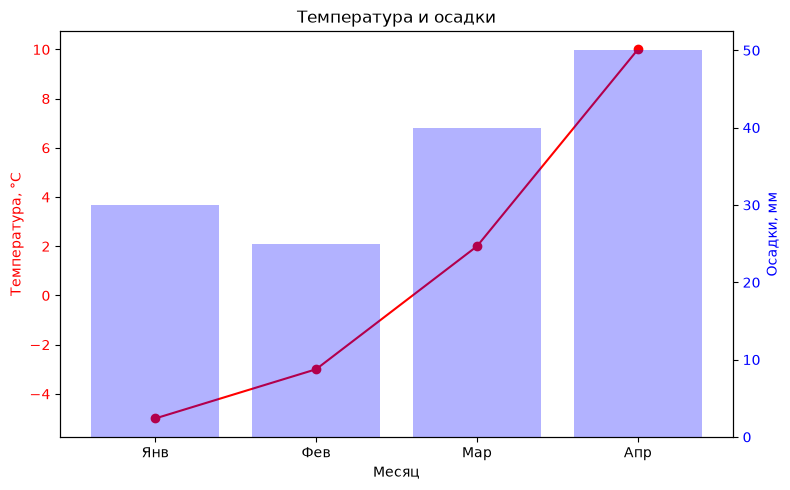

In [24]:
months = ["Янв", "Фев", "Мар", "Апр"]
temperature = [-5, -3, 2, 10]  # °C
rainfall = [30, 25, 40, 50]    # мм

fig, ax1 = plt.subplots(figsize=(8, 5))

# Первая вертикальная ось: температура
ax1.plot(months, temperature, color="red", marker="o")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Температура, °C", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Вторая вертикальная ось: осадки
ax2 = ax1.twinx()
ax2.bar(months, rainfall, color="blue", alpha=0.3)
ax2.set_ylabel("Осадки, мм", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

ax1.set_title("Температура и осадки")
fig.tight_layout()
plt.show()

## Аппроксимация - polyfir + линия поверх точек

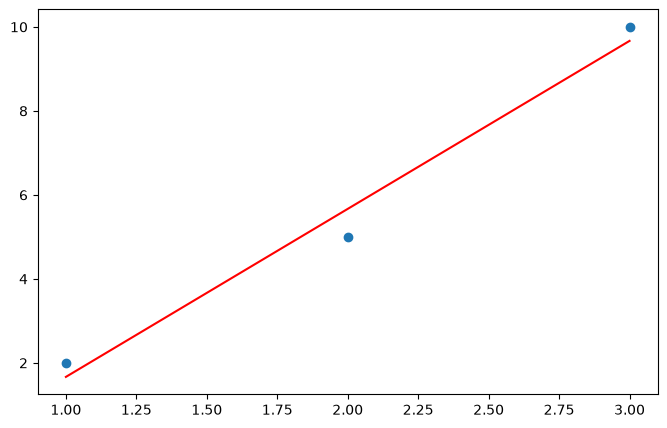

In [34]:
import numpy as np

fig, ax = plt.subplots(figsize=(8, 5))

# подбор коэффициентов прямой
# Число 1 означает многочлен первой степени — прямую вида:
k, b = np.polyfit(x, y, 1)  # коэффициенты прямой - наклон и сдвиг, степень 1 - прямая

# Создаёт массив из 100 равномерно расположенных значений от минимального до максимального x, включая границы.
xr = np.linspace(min(x), max(x), 100)

ax.scatter(x, y)
ax.plot(xr, k * xr + b, color="red")

plt.show()

## Тепловая карта

Код показывает матрицу как тепловую карту: каждой ячейке присваивается цвет в зависимости от её значения, а поверх цвета выводится само число.

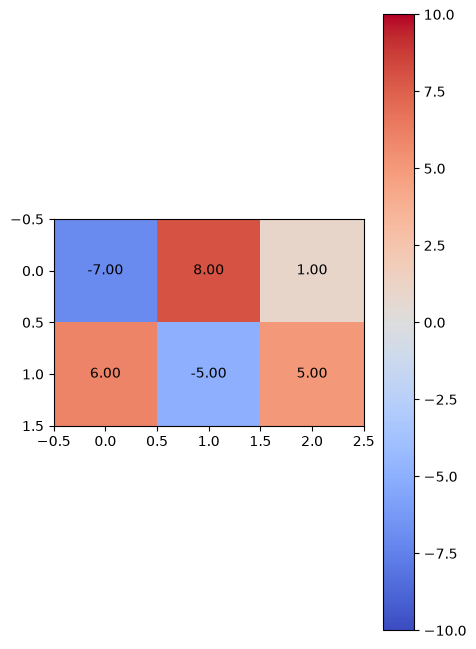

In [43]:
fig, ax = plt.subplots(figsize=(5, 8))

matrix = np.array([[-7, 8, 1], [6, -5, 5]])
# рисуем матрицу как картинку
im = plt.imshow(matrix, cmap='coolwarm', vmin=-10, vmax=10)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center')

# добавление легенды-шкалы            
fig.colorbar(im, ax=ax)

## Box-Plot с заливкой

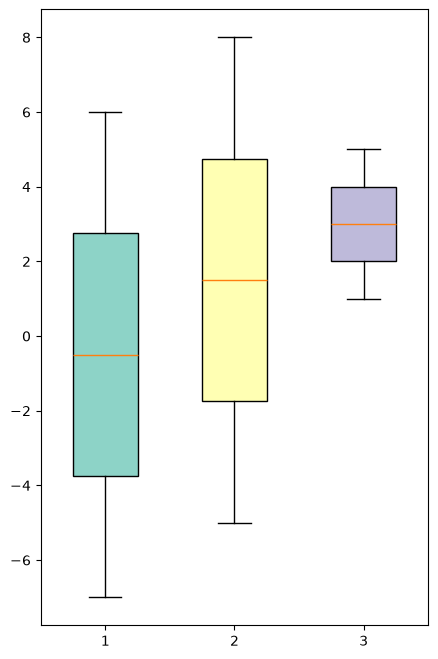

In [ ]:
fig, ax = plt.subplots(figsize=(5, 8))

# path_artist - делает коробки заливаемыми
bp = ax.boxplot(matrix, patch_artist=True, widths=0.5)

# При передаче двумерного массива boxplot() строит отдельный ящик для каждого столбца
for patch, color in zip(bp['boxes'], ['#8dd3c7', '#ffffb3', '#bebada']):
    patch.set_facecolor(color)

## Джиттер - точки поверх коробок

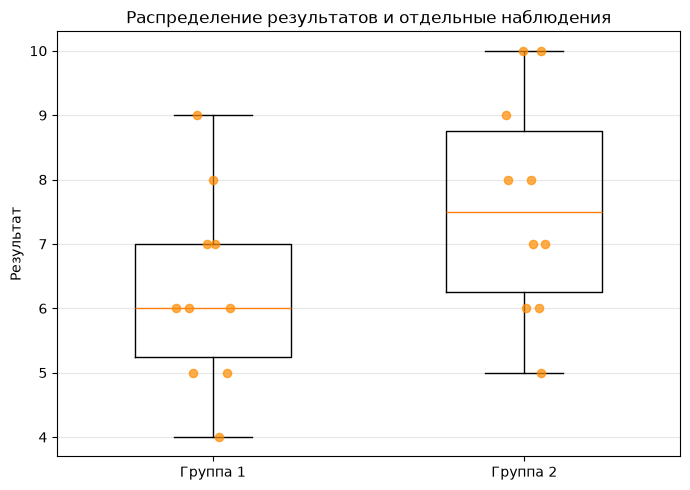

In [57]:
# Результаты двух групп: повторяющиеся значения видны благодаря джиттеру.
groups = [
    [4, 5, 5, 6, 6, 6, 7, 7, 8, 9],
    [5, 6, 6, 7, 7, 8, 8, 9, 10, 10],
]
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(groups, positions=[1, 2], widths=0.5, showfliers=False)

rng = np.random.default_rng(42)  # одинаковое расположение точек при каждом запуске
for position, values in enumerate(groups, start=1):
    xj = rng.normal(position, 0.06, size=len(values))
    ax.scatter(xj, values, s=35, alpha=0.7, color="darkorange", zorder=3)

ax.set_xticks([1, 2], ["Группа 1", "Группа 2"])
ax.set_ylabel("Результат")
ax.set_title("Распределение результатов и отдельные наблюдения")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


## Объединение двух легенд

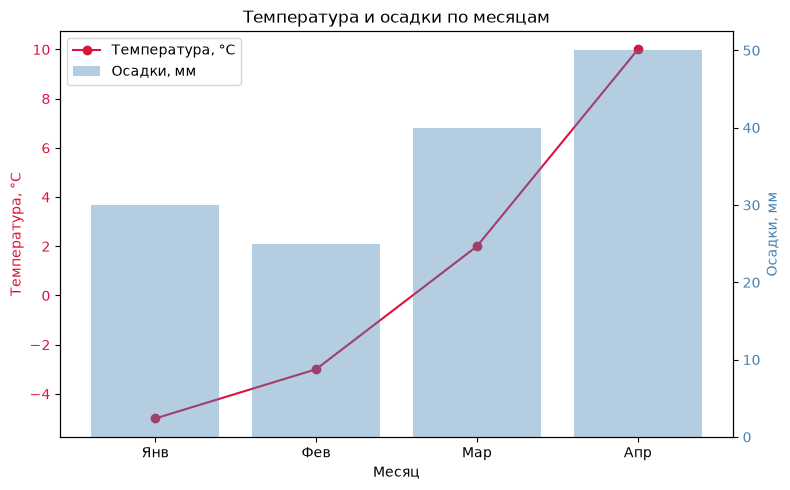

In [55]:
import matplotlib.pyplot as plt

months = ["Янв", "Фев", "Мар", "Апр"]
temperature = [-5, -3, 2, 10]  # °C
rainfall = [30, 25, 40, 50]    # мм

fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()  # общая ось X и отдельная ось Y справа

ax1.plot(months, temperature, color="crimson", marker="o", label="Температура, °C")
ax2.bar(months, rainfall, color="steelblue", alpha=0.4, label="Осадки, мм")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Температура, °C", color="crimson")
ax2.set_ylabel("Осадки, мм", color="steelblue")
ax1.tick_params(axis="y", labelcolor="crimson")
ax2.tick_params(axis="y", labelcolor="steelblue")
ax1.set_title("Температура и осадки по месяцам")

# Собираем обозначения и подписи с обеих осей в одну легенду.
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")

fig.tight_layout()
plt.show()
